# CreditGuard — Stronger Models + Reduced Inputs

This notebook keeps the workflow simple while allowing stronger classifiers.

Main goals:

1. Compare simple and advanced classifiers.
2. Improve performance beyond the earlier baseline.
3. Tune the classification threshold.
4. Measure feature importance.
5. Compare **23 inputs vs 10 inputs vs 8 inputs**.
6. Pick the best practical model using measured results.

> Educational prototype only. This model must not be used for real lending or credit decisions.


In [46]:
import io
import json
import warnings
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV

## Install and Load Advanced Classification Models

For this project, there is no restriction on which classification algorithm we can use.

Along with the Scikit-learn models, we will also compare three strong gradient-boosting libraries commonly used for structured/tabular data:

- **XGBoost**
- **LightGBM**
- **CatBoost**

These libraries are not included with Scikit-learn by default.

The following setup cell checks whether each library is installed in the current Python environment.

If a package is missing, the notebook automatically installs it using `pip`.

After installation, the required classifier classes are imported so that all three models can participate in the same model comparison.

The purpose is not to assume that one of these models will automatically perform better. All models will be evaluated using the same train/validation/test split and the same metrics.

The final model will be selected based on measured performance rather than the algorithm name.

### Models compared in this notebook

**Baseline / simpler models**

- Logistic Regression
- Decision Tree
- Support Vector Classifier
- Gaussian Naive Bayes

**Ensemble / boosting models**

- Random Forest
- Extra Trees
- Gradient Boosting
- Histogram Gradient Boosting
- XGBoost
- LightGBM
- CatBoost

The main evaluation metrics will include:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- PR-AUC

Because the target classes are imbalanced, we will not select the final model using accuracy alone.

In [23]:
import sys
import subprocess
import importlib

packages = {
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "catboost": "catboost",
}

for module_name, package_name in packages.items():
    try:
        importlib.import_module(module_name)
        print(f"{package_name} already installed")
    except ImportError:
        print(f"Installing {package_name}...")
        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            package_name
        ])

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

print("XGBoost, LightGBM, and CatBoost are ready.")

Installing xgboost...
Installing lightgbm...
Installing catboost...
XGBoost, LightGBM, and CatBoost are ready.


## 1. Load the UCI credit-card default dataset


In [25]:
UCI_URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"

response = requests.get(UCI_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    xls_files = [name for name in archive.namelist() if name.lower().endswith(".xls")]
    if not xls_files:
        raise RuntimeError("No XLS file found in the UCI archive.")
    xls_bytes = archive.read(xls_files[0])

df = pd.read_excel(io.BytesIO(xls_bytes), header=1)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Clean the data


In [26]:
df.columns = [str(col).strip() for col in df.columns]

target_column = None

for col in df.columns:
    normalized = (
        str(col)
        .strip()
        .lower()
        .replace(".", "")
        .replace("_", "")
        .replace(" ", "")
    )
    if normalized in {"defaultpaymentnextmonth", "defaultnextmonth", "y"}:
        target_column = col
        break

if target_column is None:
    raise ValueError("Target column could not be found.")

df = df.rename(columns={target_column: "DEFAULT_NEXT_MONTH"})
df = df.drop_duplicates().copy()

print("Rows:", len(df))
print("Missing values:", int(df.isna().sum().sum()))
print("Target distribution:")
print(df["DEFAULT_NEXT_MONTH"].value_counts())


Rows: 30000
Missing values: 0
Target distribution:
DEFAULT_NEXT_MONTH
0    23364
1     6636
Name: count, dtype: int64


## 3. Basic EDA


DEFAULT_NEXT_MONTH
0    77.88
1    22.12
Name: proportion, dtype: float64


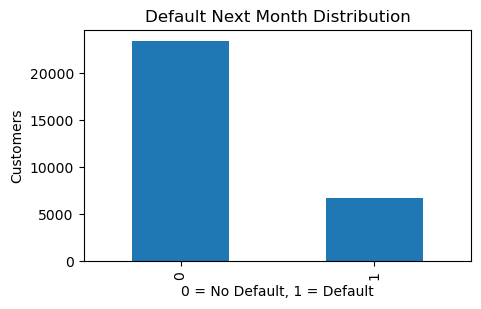

In [27]:
print((df["DEFAULT_NEXT_MONTH"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 3))
df["DEFAULT_NEXT_MONTH"].value_counts().sort_index().plot(kind="bar")
plt.title("Default Next Month Distribution")
plt.xlabel("0 = No Default, 1 = Default")
plt.ylabel("Customers")
plt.show()


## 4. Full input feature set


In [28]:
FULL_RAW_FEATURES = [
    "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]

X_raw = df[FULL_RAW_FEATURES].copy()
y = df["DEFAULT_NEXT_MONTH"].astype(int).copy()

print("Full raw input count:", len(FULL_RAW_FEATURES))


Full raw input count: 23


## 5. Simple feature engineering


In [29]:
def add_full_features(data):
    data = data.copy()

    bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
    payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
    status_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

    data["AVG_BILL_AMT"] = data[bill_cols].mean(axis=1)
    data["TOTAL_PAY_AMT"] = data[payment_cols].sum(axis=1)
    data["MAX_PAY_DELAY"] = data[status_cols].max(axis=1)
    data["AVG_PAY_STATUS"] = data[status_cols].mean(axis=1)

    safe_limit = data["LIMIT_BAL"].replace(0, np.nan)
    safe_recent_bill = data["BILL_AMT1"].replace(0, np.nan)

    data["RECENT_BILL_TO_LIMIT_RATIO"] = (data["BILL_AMT1"] / safe_limit).fillna(0)
    data["RECENT_PAY_TO_BILL_RATIO"] = (data["PAY_AMT1"] / safe_recent_bill).fillna(0)

    return data.replace([np.inf, -np.inf], 0)

X_full = add_full_features(X_raw)

print("Feature count after engineering:", X_full.shape[1])


Feature count after engineering: 29


## 6. Train / validation / test split

- Training set: train the model
- Validation set: tune the classification threshold
- Test set: final evaluation


In [30]:
X_train_full, X_temp_full, y_train, y_temp = train_test_split(
    X_full,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42,
)

X_val_full, X_test_full, y_val, y_test = train_test_split(
    X_temp_full,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42,
)

print("Training rows:", len(X_train_full))
print("Validation rows:", len(X_val_full))
print("Testing rows:", len(X_test_full))


Training rows: 21000
Validation rows: 4500
Testing rows: 4500


## 7. Preprocessing

- No one-hot encoding.
- `OrdinalEncoder` for categorical input columns.
- Target is already `0/1`, so no LabelEncoder is needed.
- Numeric values use median imputation.
- Scaling is used only for models that benefit from it.


In [31]:
def make_preprocessor(feature_names, scale_numeric=True):
    categorical = [
        col for col in ["SEX", "EDUCATION", "MARRIAGE"]
        if col in feature_names
    ]
    numeric = [col for col in feature_names if col not in categorical]

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = [
        ("numeric", Pipeline(numeric_steps), numeric),
    ]

    if categorical:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                ),
            ),
        ])

        transformers.append(
            ("categorical", categorical_pipeline, categorical)
        )

    return ColumnTransformer(transformers)


## 8. Build all candidate models


In [33]:
def build_models(feature_names):
    models = {
        "Logistic Regression": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=True)),
            ("model", LogisticRegression(
                max_iter=1500,
                class_weight="balanced",
                solver="liblinear",
                random_state=42,
            )),
        ]),

        "Decision Tree": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", DecisionTreeClassifier(
                max_depth=6,
                min_samples_leaf=20,
                class_weight="balanced",
                random_state=42,
            )),
        ]),

        "Random Forest": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", RandomForestClassifier(
                n_estimators=300,
                max_depth=12,
                min_samples_leaf=4,
                class_weight="balanced",
                n_jobs=-1,
                random_state=42,
            )),
        ]),

        "Extra Trees": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", ExtraTreesClassifier(
                n_estimators=300,
                max_depth=12,
                min_samples_leaf=3,
                class_weight="balanced",
                n_jobs=-1,
                random_state=42,
            )),
        ]),

        "SVC RBF": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=True)),
            ("model", SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced",
                random_state=42,
            )),
        ]),

        "Gaussian Naive Bayes": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=True)),
            ("model", GaussianNB()),
        ]),

        "Gradient Boosting": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", GradientBoostingClassifier(
                n_estimators=180,
                learning_rate=0.05,
                max_depth=3,
                random_state=42,
            )),
        ]),

        "Histogram Gradient Boosting": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", HistGradientBoostingClassifier(
                learning_rate=0.06,
                max_iter=220,
                max_leaf_nodes=31,
                l2_regularization=0.25,
                class_weight="balanced",
                random_state=42,
            )),
        ]),

        "XGBoost": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", XGBClassifier(
                n_estimators=350,
                max_depth=4,
                learning_rate=0.04,
                subsample=0.9,
                colsample_bytree=0.9,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1,
            )),
        ]),

        "LightGBM": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", LGBMClassifier(
                n_estimators=350,
                learning_rate=0.04,
                num_leaves=31,
                class_weight="balanced",
                random_state=42,
                verbosity=-1,
            )),
        ]),

        "CatBoost": Pipeline([
            ("preprocessor", make_preprocessor(feature_names, scale_numeric=False)),
            ("model", CatBoostClassifier(
                iterations=350,
                learning_rate=0.04,
                depth=6,
                loss_function="Logloss",
                verbose=False,
                random_seed=42,
            )),
        ])
    }

    return models


## 9. Evaluation helper functions


In [34]:
def get_scores(model, X):
    estimator = model.named_steps["model"]

    if hasattr(estimator, "predict_proba"):
        return model.predict_proba(X)[:, 1]

    decision = model.decision_function(X)
    return 1 / (1 + np.exp(-decision))


def metrics_from_predictions(y_true, preds, scores):
    return {
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1": f1_score(y_true, preds, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC": average_precision_score(y_true, scores),
    }


def find_best_threshold(y_true, scores):
    thresholds = np.arange(0.20, 0.71, 0.01)

    best_threshold = 0.50
    best_f1 = -1

    for threshold in thresholds:
        preds = (scores >= threshold).astype(int)
        score = f1_score(y_true, preds, zero_division=0)

        if score > best_f1:
            best_f1 = score
            best_threshold = float(threshold)

    return round(best_threshold, 2)


## 10. Train and compare the full models


In [35]:
full_models = build_models(list(X_full.columns))
full_results = []
trained_full_models = {}

for name, model in full_models.items():
    print("Training:", name)

    fit_X = X_train_full
    fit_y = y_train

    # SVC can be slower, so use a smaller stratified subset.
    if name == "SVC RBF" and len(X_train_full) > 6000:
        fit_X, _, fit_y, _ = train_test_split(
            X_train_full,
            y_train,
            train_size=6000,
            stratify=y_train,
            random_state=42,
        )

    model.fit(fit_X, fit_y)

    test_scores = get_scores(model, X_test_full)
    default_preds = (test_scores >= 0.50).astype(int)

    full_results.append({
        "Model": name,
        **metrics_from_predictions(
            y_test,
            default_preds,
            test_scores,
        ),
    })

    trained_full_models[name] = model

full_results_df = (
    pd.DataFrame(full_results)
    .sort_values(["ROC_AUC", "F1"], ascending=False)
    .reset_index(drop=True)
)

full_results_df.round(4)


Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: SVC RBF
Training: Gaussian Naive Bayes
Training: Gradient Boosting
Training: Histogram Gradient Boosting
Training: XGBoost
Training: LightGBM
Training: CatBoost


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,CatBoost,0.8173,0.6623,0.3564,0.4634,0.7865,0.5650
1,XGBoost,0.8182,0.6618,0.3655,0.4709,0.7848,0.5669
2,Gradient Boosting,0.8173,0.6648,0.3524,0.4606,0.7832,0.5604
3,LightGBM,0.7647,0.4754,0.6114,0.5349,0.7829,0.5573
4,Histogram Gradient Boosting,0.7602,0.4683,0.6165,0.5323,0.7806,0.5476
5,Random Forest,0.7953,0.5360,0.5612,0.5483,0.7783,0.5495
6,Extra Trees,0.7636,0.4728,0.5934,0.5263,0.7774,0.5433
7,Decision Tree,0.7676,0.4795,0.5863,0.5276,0.7609,0.5100
8,SVC RBF,0.7367,0.4341,0.6245,0.5121,0.7526,0.4860
9,Logistic Regression,0.7236,0.4184,0.6386,0.5056,0.7340,0.4918


## 11. Best model by different metrics


In [36]:
best_accuracy_row = full_results_df.sort_values(
    "Accuracy", ascending=False
).iloc[0]

best_f1_row = full_results_df.sort_values(
    "F1", ascending=False
).iloc[0]

best_auc_row = full_results_df.sort_values(
    "ROC_AUC", ascending=False
).iloc[0]

print(
    "Best Accuracy:",
    best_accuracy_row["Model"],
    round(best_accuracy_row["Accuracy"], 4),
)

print(
    "Best F1:",
    best_f1_row["Model"],
    round(best_f1_row["F1"], 4),
)

print(
    "Best ROC-AUC:",
    best_auc_row["Model"],
    round(best_auc_row["ROC_AUC"], 4),
)

best_full_model_name = best_auc_row["Model"]
best_full_model = trained_full_models[best_full_model_name]

print("\nSelected full model:", best_full_model_name)


Best Accuracy: XGBoost 0.8182
Best F1: Random Forest 0.5483
Best ROC-AUC: CatBoost 0.7865

Selected full model: CatBoost


## 12. Tune the classification threshold


In [37]:
validation_scores = get_scores(best_full_model, X_val_full)
best_threshold = find_best_threshold(y_val, validation_scores)

test_scores = get_scores(best_full_model, X_test_full)

default_preds = (test_scores >= 0.50).astype(int)
tuned_preds = (test_scores >= best_threshold).astype(int)

default_metrics = metrics_from_predictions(
    y_test,
    default_preds,
    test_scores,
)

tuned_metrics = metrics_from_predictions(
    y_test,
    tuned_preds,
    test_scores,
)

threshold_comparison = pd.DataFrame([
    {"Threshold": 0.50, **default_metrics},
    {"Threshold": best_threshold, **tuned_metrics},
])

print("Chosen threshold:", best_threshold)
threshold_comparison.round(4)


Chosen threshold: 0.25


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,0.50,0.8173,0.6623,0.3564,0.4634,0.7865,0.565
1,0.25,0.7787,0.5000,0.6044,0.5473,0.7865,0.565


## 13. Confusion matrix


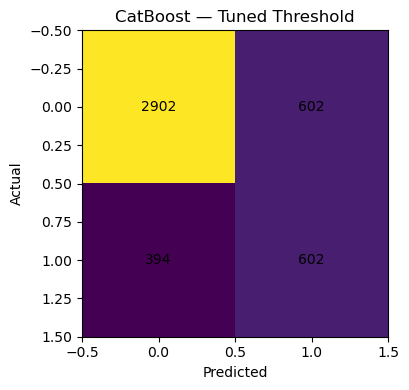

              precision    recall  f1-score   support

           0       0.88      0.83      0.85      3504
           1       0.50      0.60      0.55       996

    accuracy                           0.78      4500
   macro avg       0.69      0.72      0.70      4500
weighted avg       0.80      0.78      0.79      4500



In [38]:
cm = confusion_matrix(y_test, tuned_preds)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title(f"{best_full_model_name} — Tuned Threshold")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, int(value), ha="center", va="center")

plt.tight_layout()
plt.show()

print(classification_report(y_test, tuned_preds, zero_division=0))


## 14. Feature importance


In [39]:
importance = permutation_importance(
    best_full_model,
    X_test_full,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Feature": X_test_full.columns,
    "Importance": importance.importances_mean,
}).sort_values("Importance", ascending=False)

importance_df.head(15)


,Feature,Importance
5,PAY_0,0.046636
27,RECENT_BILL_TO_LIMIT_RATIO,0.014230
25,MAX_PAY_DELAY,0.011237
26,AVG_PAY_STATUS,0.006271
11,BILL_AMT1,0.006130
0,LIMIT_BAL,0.005576
24,TOTAL_PAY_AMT,0.005130
23,AVG_BILL_AMT,0.004610
19,PAY_AMT3,0.003618
17,PAY_AMT1,0.002689


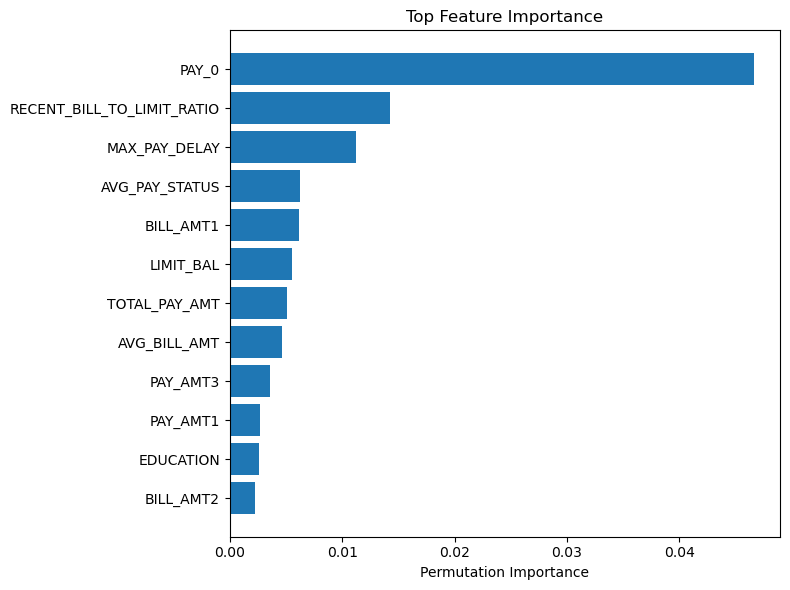

In [40]:
top_12 = importance_df.head(12).sort_values("Importance")

plt.figure(figsize=(8, 6))
plt.barh(top_12["Feature"], top_12["Importance"])
plt.title("Top Feature Importance")
plt.xlabel("Permutation Importance")
plt.tight_layout()
plt.show()


# 15. Reduced-input product models

We now test whether the user really needs all 23 raw fields.

### Compact 8-input form
- Credit limit
- Age
- Latest repayment status
- Previous repayment status
- Latest bill
- Previous bill
- Latest payment
- Previous payment

### Compact 10-input form
Same 8 plus:
- Education
- Marital status


In [41]:
COMPACT_8_FEATURES = [
    "LIMIT_BAL",
    "AGE",
    "PAY_0",
    "PAY_2",
    "BILL_AMT1",
    "BILL_AMT2",
    "PAY_AMT1",
    "PAY_AMT2",
]

COMPACT_10_FEATURES = [
    *COMPACT_8_FEATURES,
    "EDUCATION",
    "MARRIAGE",
]

print("Compact 8:", COMPACT_8_FEATURES)
print("Compact 10:", COMPACT_10_FEATURES)


Compact 8: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2']
Compact 10: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2', 'EDUCATION', 'MARRIAGE']


## 16. Train strong compact-model candidates


In [42]:
def split_raw_features(feature_list):
    X = df[feature_list].copy()

    X_train, X_temp, y_train_local, y_temp_local = train_test_split(
        X,
        y,
        test_size=0.30,
        stratify=y,
        random_state=42,
    )

    X_val, X_test, y_val_local, y_test_local = train_test_split(
        X_temp,
        y_temp_local,
        test_size=0.50,
        stratify=y_temp_local,
        random_state=42,
    )

    return (
        X_train,
        X_val,
        X_test,
        y_train_local,
        y_val_local,
        y_test_local,
    )


def build_compact_candidates(feature_list):
    all_models = build_models(feature_list)

    wanted = {
        "Random Forest",
        "Extra Trees",
        "Histogram Gradient Boosting",
        "XGBoost",
        "LightGBM",
        "CatBoost",
    }

    return {
        name: model
        for name, model in all_models.items()
        if name in wanted
    }


compact_results = []
compact_models = {}

for label, features in {
    "Compact 8 Inputs": COMPACT_8_FEATURES,
    "Compact 10 Inputs": COMPACT_10_FEATURES,
}.items():

    (
        X_train_c,
        X_val_c,
        X_test_c,
        y_train_c,
        y_val_c,
        y_test_c,
    ) = split_raw_features(features)

    candidates = build_compact_candidates(features)

    best_candidate_name = None
    best_candidate_model = None
    best_validation_auc = -1

    for candidate_name, candidate_model in candidates.items():
        candidate_model.fit(X_train_c, y_train_c)

        validation_scores = get_scores(
            candidate_model,
            X_val_c,
        )

        validation_auc = roc_auc_score(
            y_val_c,
            validation_scores,
        )

        if validation_auc > best_validation_auc:
            best_validation_auc = validation_auc
            best_candidate_name = candidate_name
            best_candidate_model = candidate_model

    validation_scores = get_scores(
        best_candidate_model,
        X_val_c,
    )

    threshold = find_best_threshold(
        y_val_c,
        validation_scores,
    )

    test_scores_c = get_scores(
        best_candidate_model,
        X_test_c,
    )

    test_preds_c = (
        test_scores_c >= threshold
    ).astype(int)

    metrics = metrics_from_predictions(
        y_test_c,
        test_preds_c,
        test_scores_c,
    )

    compact_results.append({
        "Model": label,
        "Algorithm": best_candidate_name,
        "Input_Count": len(features),
        "Threshold": threshold,
        **metrics,
    })

    compact_models[label] = {
        "model": best_candidate_model,
        "algorithm": best_candidate_name,
        "features": features,
        "threshold": threshold,
    }

compact_results_df = pd.DataFrame(compact_results)
compact_results_df.round(4)


,Model,Algorithm,Input_Count,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Compact 8 Inputs,XGBoost,8,0.25,0.7767,0.4961,0.5813,0.5354,0.7682,0.5429
1,Compact 10 Inputs,XGBoost,10,0.23,0.7640,0.4743,0.6124,0.5346,0.7715,0.5514


## 17. Full model vs reduced-input models


In [43]:
full_comparison_row = {
    "Model": f"Full Model — {best_full_model_name}",
    "Algorithm": best_full_model_name,
    "Input_Count": 23,
    "Threshold": best_threshold,
    **tuned_metrics,
}

product_comparison = pd.concat([
    pd.DataFrame([full_comparison_row]),
    compact_results_df,
], ignore_index=True)

product_comparison[
    [
        "Model",
        "Algorithm",
        "Input_Count",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC",
        "Threshold",
    ]
].round(4)


,Model,Algorithm,Input_Count,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
0,Full Model — CatBoost,CatBoost,23,0.7787,0.5000,0.6044,0.5473,0.7865,0.5650,0.25
1,Compact 8 Inputs,XGBoost,8,0.7767,0.4961,0.5813,0.5354,0.7682,0.5429,0.25
2,Compact 10 Inputs,XGBoost,10,0.7640,0.4743,0.6124,0.5346,0.7715,0.5514,0.23


## 18. Pick the practical product model

Rule:

- A compact model is acceptable if its ROC-AUC is within **0.03** of the full model.
- If both compact versions qualify, prefer fewer inputs.
- If neither qualifies, keep the full model.


In [44]:
full_auc = float(tuned_metrics["ROC_AUC"])
acceptable_drop = 0.03

acceptable_compact = compact_results_df[
    compact_results_df["ROC_AUC"] >= full_auc - acceptable_drop
].copy()

if not acceptable_compact.empty:
    acceptable_compact = acceptable_compact.sort_values(
        ["Input_Count", "ROC_AUC"],
        ascending=[True, False],
    )

    chosen_name = acceptable_compact.iloc[0]["Model"]
    chosen = compact_models[chosen_name]

    product_model = chosen["model"]
    product_features = chosen["features"]
    product_threshold = float(chosen["threshold"])
    product_algorithm = chosen["algorithm"]
    product_model_name = chosen_name
else:
    product_model = best_full_model
    product_features = FULL_RAW_FEATURES
    product_threshold = best_threshold
    product_algorithm = best_full_model_name
    product_model_name = f"Full Model — {best_full_model_name}"

print("Chosen product model:", product_model_name)
print("Algorithm:", product_algorithm)
print("User input count:", len(product_features))
print("Threshold:", product_threshold)
print("Features:", product_features)


Chosen product model: Compact 8 Inputs
Algorithm: XGBoost
User input count: 8
Threshold: 0.25
Features: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2']


## 19. Save the measured winner


In [45]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

joblib.dump(
    product_model,
    ARTIFACT_DIR / "model_stronger_notebook.joblib",
)

metadata = {
    "model_name": product_model_name,
    "algorithm": product_algorithm,
    "model_version": "notebook_v4",
    "target": "DEFAULT_NEXT_MONTH",
    "input_features": product_features,
    "input_count": len(product_features),
    "classification_threshold": product_threshold,
    "risk_thresholds": {
        "low_max": 0.20,
        "high_min": 0.40,
    },
    "note": "Educational prototype only; not a lending or credit decision.",
}

with open(
    ARTIFACT_DIR / "model_stronger_notebook_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(metadata, file, indent=2)

print(
    "Saved:",
    ARTIFACT_DIR / "model_stronger_notebook.joblib",
)

print(
    "Saved:",
    ARTIFACT_DIR / "model_stronger_notebook_metadata.json",
)


Saved: artifacts\model_stronger_notebook.joblib
Saved: artifacts\model_stronger_notebook_metadata.json


# Send me these results after running

Please send:

1. `full_results_df`
2. `threshold_comparison`
3. `product_comparison`
4. `Chosen product model`
5. `Algorithm`

Those results will determine the exact model and input fields we use in FastAPI and Flutter.
